<a href="https://colab.research.google.com/github/Mera-15/ProcesamientoDelHabla/blob/main/Rodriguez_Maria_Eugenia_TP3_chatbot_retrieval_template_parte_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TP3 Chatbots basados en recuperación de la información

En inglés information retrieval chatbots

# Motor de búsqueda

* Búsqueda por palabras clave: Extrae palabras clave de la pregunta del usuario y busca coincidencias en las preguntas almacenadas.

* Similitud del coseno: Si has representado las preguntas como vectores (por ejemplo, usando TF-IDF o word embeddings), puedes usar la similitud del coseno para medir la distancia entre las preguntas.

* Embeddings: Utiliza modelos de word embeddings como por ejemplo Word2Vec para obtener representaciones semánticas de las preguntas y las consultas del usuario.

## Librerías

Debes trabajar en Python. Puedes usar las librerías sklearn, pandas, spacy o nltk o gensim para el punto de usar o buscar embeddings.

In [2]:
!pip install spacy --quiet
!python -m spacy download es_core_news_md --quiet
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.3/42.3 MB 36.2 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('es_core_news_md')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


## Actividades



### 1) Elaborar un dataset de preguntas y respuestas para crear un Chatbot para un aplicación particular. ( 3 puntos )

1.1 Debe definir la aplicación (atención al cliente bancario, atención a estudiantes universitarios, etc).

1.2 El listado de preguntas y respuestas debe tener como mínimo 20 elementos pregunta - respuesta.

###  2) Crear el chatbot utilizando TFIDF y similitud del coseno. (1 punto)

### 3) Crear otro chatbot utilizando embeddings. Indique cuál embedding (1 punto) pre-entrenado de las librerías Spacy o nltk o gensim eligió. Justifique.

### 4) Muestra ambos chatbots funcionando (1 punto)

Adjuntar la lista de preguntas y respuestas utilizadas para probar el funcionamiento.

Releve o indique cuáles respondió correctamente y cuáles no.

### 5) Añade tus conclusiones de todo lo realizado (2 punto)

* Resalte e indique en cuáles respuestas falla o tiene problemas.
* Cuáles preguntas confunde.
* Compare los resultados de los chatbots.



### No olvides:

* Explicar tus decisiones y configuraciones. Añadir tus conclusiones.
* Anunciar en el foro cuál será tu aplicación y postear tu entrega y tus avances.
* Debes subir tu notebook a un repo GitHub público de tu propiedad compartido + enlace colab.
* Documentar todo el proceso.
* Citar tus fuentes





## 🟣 Enlace al dataset:

https://docs.google.com/spreadsheets/d/1TdAFqLw2vkHhFoFNZnHNeGDnMMdFvQOvP14bgQC0gOc/edit?usp=sharing

Voy a crear un chatbot para un gimnasio.
Para esto, primero voy a crear un dataset en una hoja de cálculo, con posibles preguntas de los clientes y respuestas posibles del chatbot a esas preguntas.

# 🟣 Chatbot con TF-IDF

Cargo el dataset en un repositorio público en Github para que sea accesible en caso de que se quiera interactuar con el notebook.
Previamente se instaló SpaCy para el procesamiento de texto y se descargó el modelo preentrenado en español es_core_news_md.

Se eligió el md porque es un intermedio que me pareció apropiado para este trabajo, ni muy chico, ni muy grande.

In [54]:
# Se importa pandas para el manejo de dataframes.
import pandas as pd

# Se guarda la url en una variable.
url_dataset = 'https://github.com/Mera-15/ProcesamientoDelHabla/raw/refs/heads/main/Dataset_preguntas_respuestas_gimnasio.xlsx'

# Se le pide a pandas que lea el dataset y que lo guarde en una variable.
df = pd.read_excel(url_dataset)

# Se muestran las primeras 5 filas.
df.head()

,Preguntas,Respuestas
0,¿Qué horario tienen?,Lunes a viernes de 7:00 a 20:00 y sábados de 9...
1,¿Los feriados abre?,Los feriados el gimnasio se encuentra cerrado.
2,¿De cuánto es la cuota?,La cuota mensual es de $30000. Varía según dis...
3,¿Qué disciplinas hay?,"Las disciplinas disponibles son: musculación, ..."
4,¿Qué horarios tienen las disciplinas?,"Horarios:\nMusculación: lunes, miércoles y vie..."


In [55]:
# Se importa la librería SpaCy.
import spacy
# Se carga el modelo y se guarda en una variable.
nlp = spacy.load('es_core_news_md')

# Se crea una función que limpia cada texto del dataset.
def limpieza_dataset(texto):
  # Se pasa el texto a minúscula y se procesa con SpaCy.
  doc = nlp(texto.lower())
  # Se crea una lista vacía para guardar los tokens.
  tokens_limpios = []

  for palabra in doc:
    # Se verifica que no sea una stopword y no sea puntuación.
    if not palabra.is_stop and not palabra.is_punct:
      # Se guarda el "lema" (la raíz) de la palabra en la lista.
      tokens_limpios.append(palabra.lemma_)

  # Se unen los tokens limpios en una sola frase y se devuelve el resultado.
  return ' '.join(tokens_limpios)

In [56]:
# Se aplica la función a la columna original y se crea una nueva.
df['Preguntas_Limpias'] = df['Preguntas'].apply(limpieza_dataset)

# Se muestran las primeras 5 filas.
df.head()

,Preguntas,Respuestas,Preguntas_Limpias
0,¿Qué horario tienen?,Lunes a viernes de 7:00 a 20:00 y sábados de 9...,horario
1,¿Los feriados abre?,Los feriados el gimnasio se encuentra cerrado.,feriado abrir
2,¿De cuánto es la cuota?,La cuota mensual es de $30000. Varía según dis...,cuota
3,¿Qué disciplinas hay?,"Las disciplinas disponibles son: musculación, ...",disciplina
4,¿Qué horarios tienen las disciplinas?,"Horarios:\nMusculación: lunes, miércoles y vie...",horario disciplina


In [70]:
# Se inicializa el vectorizador TF-IDF.
vectorizer = TfidfVectorizer()

# Se entrena el modelo y se transforman las preguntas limpias en una matriz matemática.
tfidf_matrix = vectorizer.fit_transform(df['Preguntas_Limpias'])

# Se comprueban las dimensiones de la matriz generada.
print(f'Dimensiones de la matriz TF-IDF: {tfidf_matrix.shape}')

Dimensiones de la matriz TF-IDF: (20, 39)


In [58]:
# Se importa NumPy para trabajar con los vectores.
import numpy as np

def chatbot_tfidf(pregunta_usuario):
  # Se limpia la nueva pregunta usando la función antes creada.
  pregunta_limpia = limpieza_dataset(pregunta_usuario)

  # Se transforma el texto a vector.
  vector_usuario = vectorizer.transform([pregunta_limpia])

  # Se calcula la similitud del coseno contra todas las preguntas del dataset.
  similitudes = cosine_similarity(vector_usuario, tfidf_matrix)

  # Se busca la fila con el puntaje de similitud más alto.
  indice_ganador = np.argmax(similitudes)
  puntaje_maximo = similitudes[0, indice_ganador]

  # Filtro de seguridad: si el puntaje es muy bajo, se asume que no se entendió.
  if puntaje_maximo > 0.1:
    return df['Respuestas'].iloc[indice_ganador]
  else:
    return 'Perdón, no entendí tu pregunta. ¿Podrías reformularla?'

# Prueba.
consulta = 'Hola, a qué hora abren a la mañana?'
print('Usuario: ', consulta)
print('Chatbot: ', chatbot_tfidf(consulta))

Usuario:  Hola, a qué hora abren a la mañana?
Chatbot:  Los feriados el gimnasio se encuentra cerrado.


Acá el modelo se confundió porque la palabra horario aparece más veces que la palabra abrir, por lo tanto le da más peso a ésta última y considera la respuesta brindada como la más acertada.

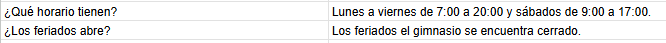

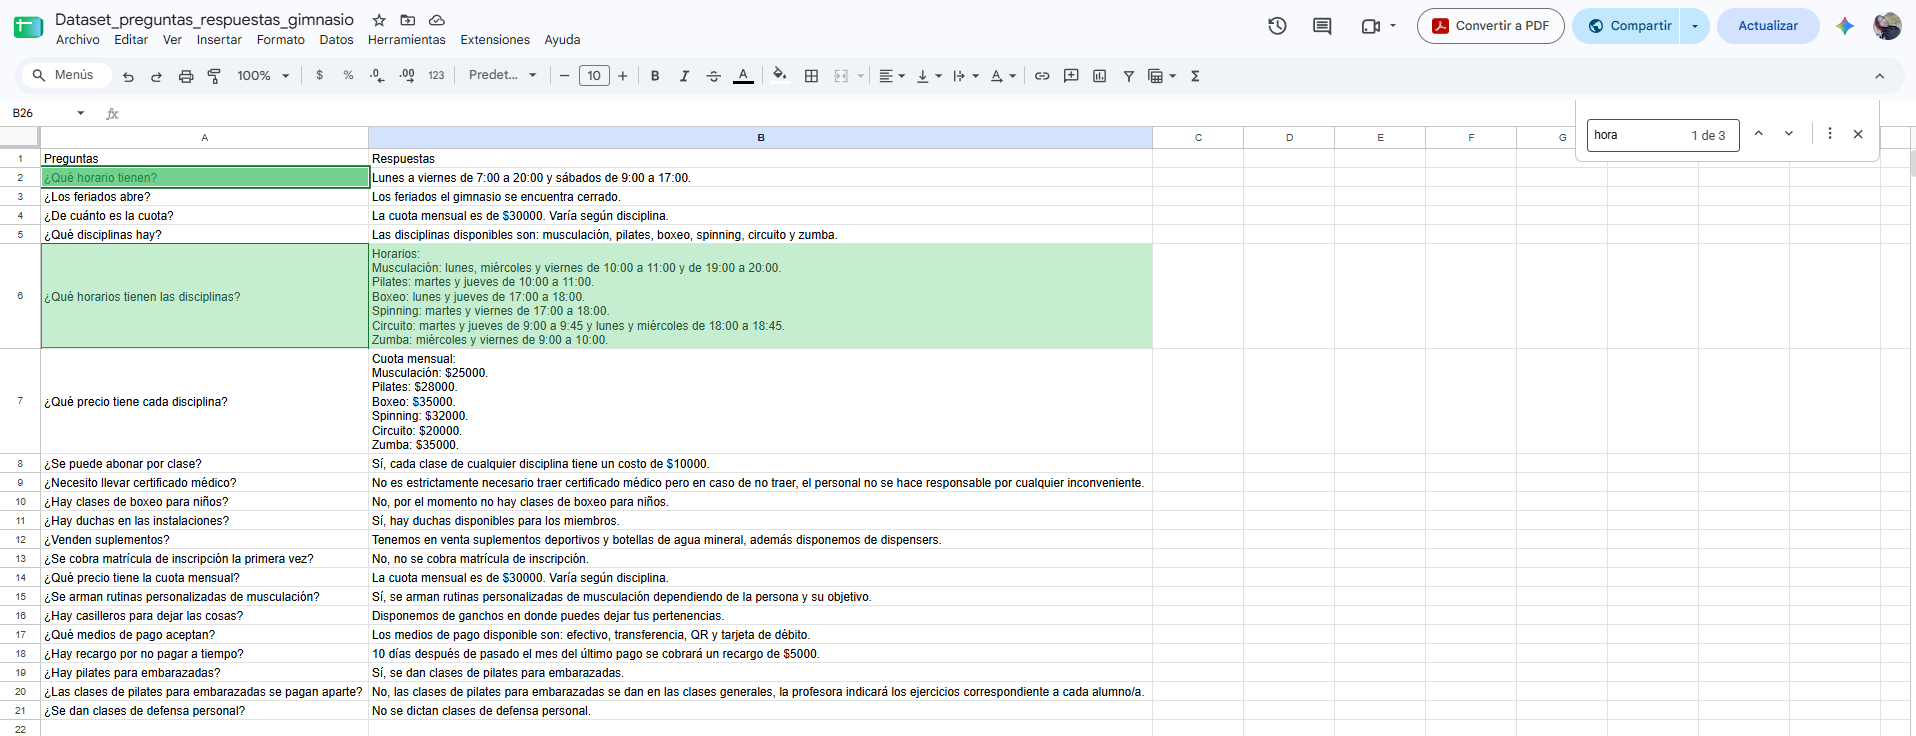

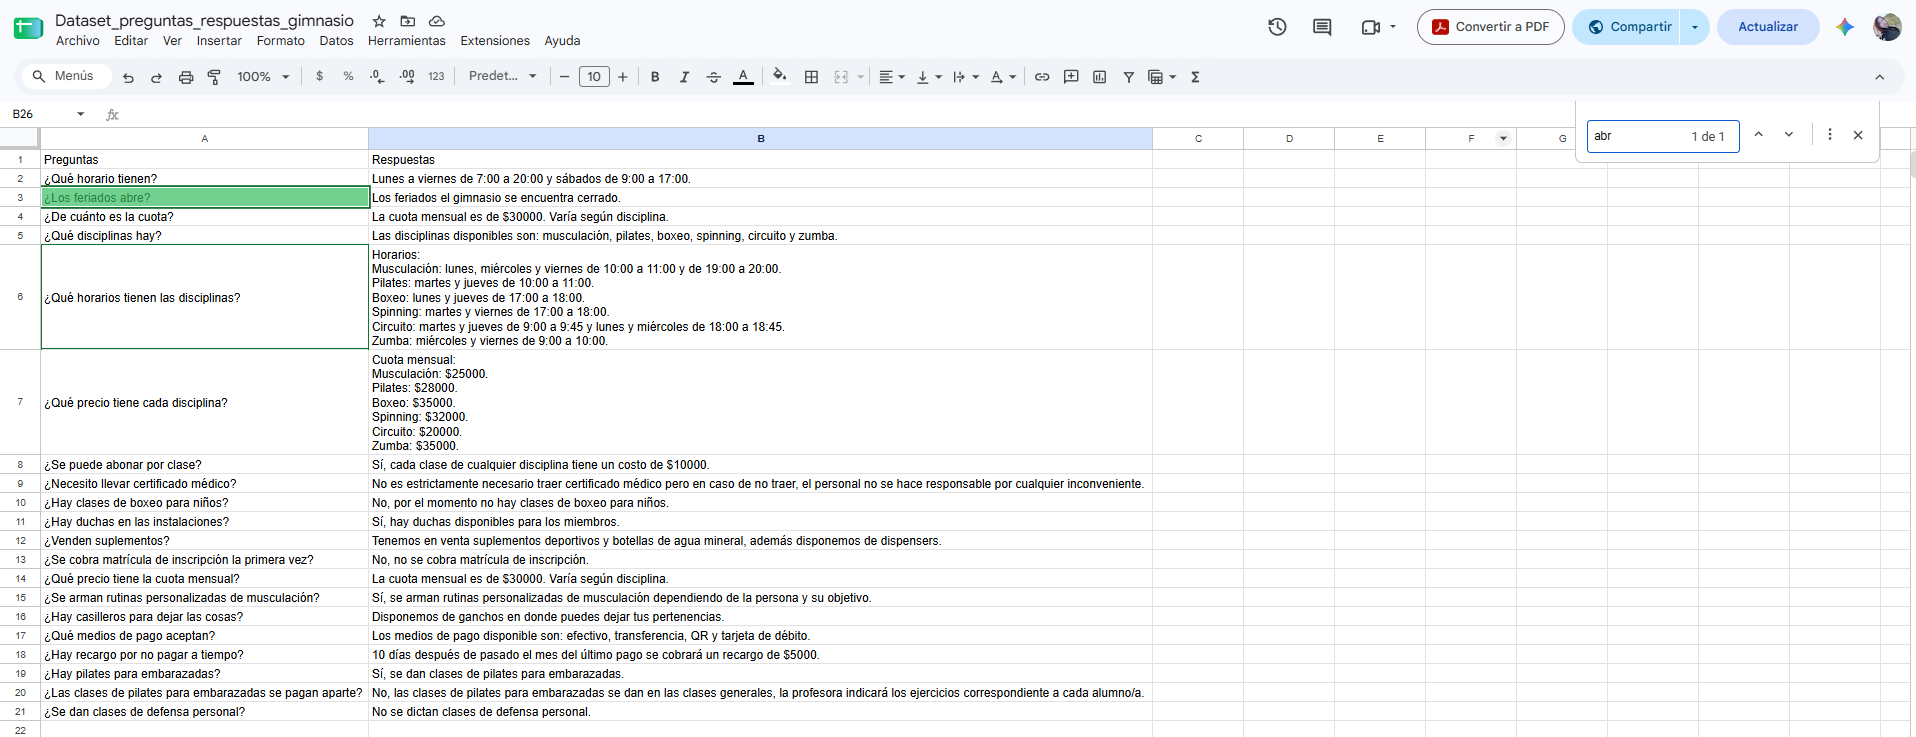

In [59]:
import pandas as pd
import numpy as np

# Se crea una función para evaluar listas de preguntas.
def evaluar_modelo_tfidf(lista_preguntas):
  resultados = []

  for pregunta in lista_preguntas:
    # Se limpia y se transforma la pregunta.
    pregunta_limpia = limpieza_dataset(pregunta)
    vector_usuario = vectorizer.transform([pregunta_limpia])

    # Se calculan similitudes.
    similitudes = cosine_similarity(vector_usuario, tfidf_matrix)

    # Se extrae el mejor puntaje y su respuesta.
    indice_ganador = np.argmax(similitudes)
    puntaje_maximo = similitudes[0, indice_ganador]
    respuesta = df['Respuestas'].iloc[indice_ganador]

    # Se guardan los datos en la lista.
    resultados.append({
        'Pregunta del Usuario': pregunta,
        'Similitud(Coseno)': round(puntaje_maximo, 4),
        'Respuesta Modelo': respuesta[:50] + '...' # Se recorta la respuesta para que la tabla sea legible.
    })

  # Se convierten los resultados en un DataFrame para que se vea como tabla.
  return pd.DataFrame(resultados)

# --- PRUEBA 1: PREGUNTAS EXACTAS DEL DATASET ---
# Se convierte la columna del dataset en una lista y se evalúa.
df_prueba_exactas = evaluar_modelo_tfidf(df['Preguntas'].tolist())
print('Resultados con preguntas exactas del dataset:')
display(df_prueba_exactas.head(20)) # Se muestran las preguntas.

# --- PRUEBA 2: PREGUNTAS DISTINTAS/PARECIDAS ---
preguntas_variadas = [
    '¿Cuánto cuesta la cuota mensual?',
    'Hola, abren mañana?',
    '¿Tienen lockers para guardar la mochila?',
    '¿Abre los días feriados?',
    'Pasame el precio de la cuota'
]

df_prueba_variadas = evaluar_modelo_tfidf(preguntas_variadas)
print('\nResultados con preguntas variadas:')
display(df_prueba_variadas)

Resultados con preguntas exactas del dataset:


,Pregunta del Usuario,Similitud(Coseno),Respuesta Modelo
0,¿Qué horario tienen?,1.0,Lunes a viernes de 7:00 a 20:00 y sábados de 9...
1,¿Los feriados abre?,1.0,Los feriados el gimnasio se encuentra cerrado....
2,¿De cuánto es la cuota?,1.0,La cuota mensual es de $30000. Varía según dis...
3,¿Qué disciplinas hay?,1.0,"Las disciplinas disponibles son: musculación, ..."
4,¿Qué horarios tienen las disciplinas?,1.0,"Horarios:\nMusculación: lunes, miércoles y vie..."
5,¿Qué precio tiene cada disciplina?,1.0,Cuota mensual:\nMusculación: $25000.\nPilates:...
6,¿Se puede abonar por clase?,1.0,"Sí, cada clase de cualquier disciplina tiene u..."
7,¿Necesito llevar certificado médico?,1.0,No es estrictamente necesario traer certificad...
8,¿Hay clases de boxeo para niños?,1.0,"No, por el momento no hay clases de boxeo para..."
9,¿Hay duchas en las instalaciones?,1.0,"Sí, hay duchas disponibles para los miembros...."



Resultados con preguntas variadas:


,Pregunta del Usuario,Similitud(Coseno),Respuesta Modelo
0,¿Cuánto cuesta la cuota mensual?,0.8345,La cuota mensual es de $30000. Varía según dis...
1,"Hola, abren mañana?",0.7071,Los feriados el gimnasio se encuentra cerrado....
2,¿Tienen lockers para guardar la mochila?,0.0000,Lunes a viernes de 7:00 a 20:00 y sábados de 9...
3,¿Abre los días feriados?,1.0000,Los feriados el gimnasio se encuentra cerrado....
4,Pasame el precio de la cuota,0.7792,La cuota mensual es de $30000. Varía según dis...


En el bloque anterior el chatbot respondía a cualquier pregunta aunque no tuviera nada que ver, por eso en el siguiente bloque se agrega una condición para que cuando la similitud sea casi nula el chatbot responda "No entiendo la pregunta".

In [60]:
import pandas as pd
import numpy as np

# Se crea una función para evaluar listas de preguntas.
def evaluar_modelo_tfidf(lista_preguntas):
  resultados = []

  for pregunta in lista_preguntas:
    # Se limpia y se transforma la pregunta.
    pregunta_limpia = limpieza_dataset(pregunta)
    vector_usuario = vectorizer.transform([pregunta_limpia])

    # Se calculan similitudes.
    similitudes = cosine_similarity(vector_usuario, tfidf_matrix)

    # Se extrae el mejor puntaje y su respuesta.
    indice_ganador = np.argmax(similitudes)
    puntaje_maximo = similitudes[0, indice_ganador]

    # Se agrega una condición.
    if puntaje_maximo > 0.1: # Si la similitud es mayor al 10%.
      respuesta = df['Respuestas'].iloc[indice_ganador]
    else:
      respuesta = 'No entiendo la pregunta. ¿Podrías reformularla?'

    # Se guardan los datos en la lista.
    resultados.append({
        'Pregunta del Usuario': pregunta,
        'Similitud(Coseno)': round(puntaje_maximo, 4),
        'Respuesta Modelo': respuesta[:50] + '...' # Se recorta la respuesta para que la tabla sea legible.
    })

  # Se convierten los resultados en un DataFrame para que se vea como tabla.
  return pd.DataFrame(resultados)

# --- PRUEBA 1: PREGUNTAS EXACTAS DEL DATASET ---
# Se convierte la columna del dataset en una lista y se evalúa.
df_prueba_exactas = evaluar_modelo_tfidf(df['Preguntas'].tolist())
print('Resultados con preguntas exactas del dataset:')
display(df_prueba_exactas.head(20)) # Se muestran las preguntas.

# --- PRUEBA 2: PREGUNTAS DISTINTAS/PARECIDAS ---
preguntas_variadas = [
    '¿Cuánto cuesta la cuota mensual?',
    'Hola, abren mañana?',
    '¿Tienen lockers para guardar la mochila?',
    '¿Abre los días feriados?',
    'Pasame el precio de la cuota'
]

df_prueba_variadas = evaluar_modelo_tfidf(preguntas_variadas)
print('\nResultados con preguntas variadas:')
display(df_prueba_variadas)

Resultados con preguntas exactas del dataset:


,Pregunta del Usuario,Similitud(Coseno),Respuesta Modelo
0,¿Qué horario tienen?,1.0,Lunes a viernes de 7:00 a 20:00 y sábados de 9...
1,¿Los feriados abre?,1.0,Los feriados el gimnasio se encuentra cerrado....
2,¿De cuánto es la cuota?,1.0,La cuota mensual es de $30000. Varía según dis...
3,¿Qué disciplinas hay?,1.0,"Las disciplinas disponibles son: musculación, ..."
4,¿Qué horarios tienen las disciplinas?,1.0,"Horarios:\nMusculación: lunes, miércoles y vie..."
5,¿Qué precio tiene cada disciplina?,1.0,Cuota mensual:\nMusculación: $25000.\nPilates:...
6,¿Se puede abonar por clase?,1.0,"Sí, cada clase de cualquier disciplina tiene u..."
7,¿Necesito llevar certificado médico?,1.0,No es estrictamente necesario traer certificad...
8,¿Hay clases de boxeo para niños?,1.0,"No, por el momento no hay clases de boxeo para..."
9,¿Hay duchas en las instalaciones?,1.0,"Sí, hay duchas disponibles para los miembros...."



Resultados con preguntas variadas:


,Pregunta del Usuario,Similitud(Coseno),Respuesta Modelo
0,¿Cuánto cuesta la cuota mensual?,0.8345,La cuota mensual es de $30000. Varía según dis...
1,"Hola, abren mañana?",0.7071,Los feriados el gimnasio se encuentra cerrado....
2,¿Tienen lockers para guardar la mochila?,0.0000,No entiendo la pregunta. ¿Podrías reformularla...
3,¿Abre los días feriados?,1.0000,Los feriados el gimnasio se encuentra cerrado....
4,Pasame el precio de la cuota,0.7792,La cuota mensual es de $30000. Varía según dis...


In [72]:
# --- PRUEBA 3: CHAT INTERACTIVO ---
print('¡Bienvenido/a al asistente virtual del Gimnasio!')
print('(Escriba "salir" para terminar la prueba)\n')

while True:
  pregunta_inventada = input('Tu pregunta: ')

  if pregunta_inventada.lower() == 'salir':
    print('Chat finalizado.')
    break

  # Se procesa la pregunta del usuario.
  pregunta_limpia = limpieza_dataset(pregunta_inventada)
  vector_usuario = vectorizer.transform([pregunta_limpia])
  similitudes = cosine_similarity(vector_usuario, tfidf_matrix)

  indice_ganador = np.argmax(similitudes)
  puntaje_maximo = similitudes[0, indice_ganador]

  print(f'[Similitud matemática: {puntaje_maximo: .4f}]')
  if puntaje_maximo > 0.1:
    print(f'Chatbot: {df["Respuestas"].iloc[indice_ganador]}\n')
  else:
    print('Chatbot: No entiendo la pregunta. ¿Podrías reformularla?\n')
  print('-' * 50)

¡Bienvenido/a al asistente virtual del Gimnasio!
(Escriba "salir" para terminar la prueba)

Tu pregunta: Salir
Chat finalizado.


# 🟣 Chatbot con Embeddings

In [62]:
import numpy as np

# Se crea una función que procesa el texto limpio con SpaCy y devuelve su vector.
def obtener_vector(texto):
  # nlp() procesa el texto y .vector extrae las coordenadas matemáticas.
  return nlp(texto).vector

# Se aplica la función a las preguntas limpias y se guardan los vectores en una nueva columna.
df['Vector_SpaCy'] = df['Preguntas_Limpias'].apply(obtener_vector)

# Se muestra la tabla.
display(df[['Preguntas_Limpias', 'Vector_SpaCy']].head(20))

,Preguntas_Limpias,Vector_SpaCy
0,horario,"[-0.39793, 1.1508, 1.2543, -3.1306, -0.30515, ..."
1,feriado abrir,"[-0.35114, 0.98968, 0.014050007, 1.2949375, 0...."
2,cuota,"[2.5158, 2.7801, -3.0553, -1.6861, 0.67698, -3..."
3,disciplina,"[1.2665, 0.83517, -0.024714, -0.53456, 0.24375..."
4,horario disciplina,"[0.43428499, 0.992985, 0.614793, -1.83258, -0...."
5,precio disciplina,"[0.56086, 1.313385, -1.515107, 0.59246993, 0.4..."
6,abonar clase,"[1.946015, 1.7518699, 0.85191, 0.98257005, 0.1..."
7,necesitar certificado médico,"[-0.03210668, 0.78604, -1.0695733, -1.4035233,..."
8,clase boxeo niño,"[1.1013867, 1.6207466, -1.8725233, 1.7838168, ..."
9,ducha instalación,"[0.3535, 0.68325, 1.3927699, 1.179253, -0.2514..."


In [63]:
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

def chatbot_spacy(pregunta_usuario):
  # Se limpia la pregunta y se calcula su vector usando la función que se armó antes.
  pregunta_limpia = limpieza_dataset(pregunta_usuario)
  vector_usuario = obtener_vector(pregunta_limpia)

  # Se apilan todos los vectores del DataFrame en una sola matriz para compararlos juntos.
  matriz_vectores = np.vstack(df['Vector_SpaCy'])

  # Se calcula la similitud.
  similitudes = cosine_similarity([vector_usuario], matriz_vectores) # vector_usuario se pone entre corchetes porque sklearn usa formato lista.

  # Se busca el mayor puntaje.
  indice_ganador = np.argmax(similitudes)
  puntaje_maximo = similitudes[0, indice_ganador]

  # Filtro de seguridad: los puntajes de los embeddings suelen ser más altos, por lo que se aumenta el umbral de corte.
  if puntaje_maximo > 0.5:
    return df['Respuestas'].iloc[indice_ganador]
  else:
    return 'Perdón, no entiendo la pregunta. ¿Podrías reformularla?'

# Se hace la prueba.
consulta = '¿Tienen lockers para guardar la mochila?'
print(f'Usuario: {consulta}')
print(f'Chatbot: {chatbot_spacy(consulta)}')

Usuario: ¿Tienen lockers para guardar la mochila?
Chatbot: Perdón, no entiendo la pregunta. ¿Podrías reformularla?


El umbral de 0.5 resultó ser muy estricto para anglicismos cotidianos como "lockers", haciendo que el modelo falle. Se agregaron unos prints para ver qué puntaje matemático real le estaba asignando.

In [64]:
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

def chatbot_spacy(pregunta_usuario):
  # Se limpia la pregunta y se calcula su vector usando la función que se armó antes.
  pregunta_limpia = limpieza_dataset(pregunta_usuario)
  vector_usuario = obtener_vector(pregunta_limpia)

  # Se apilan todos los vectores del DataFrame en una sola matriz para compararlos juntos.
  matriz_vectores = np.vstack(df['Vector_SpaCy'])

  # Se calcula la similitud.
  similitudes = cosine_similarity([vector_usuario], matriz_vectores) # vector_usuario se pone entre corchetes porque sklearn usa formato lista.

  # Se busca el mayor puntaje.
  indice_ganador = np.argmax(similitudes)
  puntaje_maximo = similitudes[0, indice_ganador]

  print(f'\nPregunta más cercana en el dataset: {df["Preguntas"].iloc[indice_ganador]}')
  print(f'Puntaje matemático exacto: {puntaje_maximo:.4f}\n')

  # Filtro de seguridad: los puntajes de los embeddings suelen ser más altos, por lo que se aumenta el umbral de corte.
  if puntaje_maximo > 0.5:
    return df['Respuestas'].iloc[indice_ganador]
  else:
    return 'Perdón, no entiendo la pregunta. ¿Podrías reformularla?'

# Se hace la prueba.
consulta = '¿Tienen lockers para guardar la mochila?'
print(f'Usuario: {consulta}')
print(f'Chatbot: {chatbot_spacy(consulta)}')

Usuario: ¿Tienen lockers para guardar la mochila?

Pregunta más cercana en el dataset: ¿Hay casilleros para dejar las cosas?
Puntaje matemático exacto: 0.3968

Chatbot: Perdón, no entiendo la pregunta. ¿Podrías reformularla?


Al verificar que el puntaje de "lockers" era de 0.39, se ajustó empíricamente el umbral a 0.35 para flexibilizar el modelo sin perder seguridad.

In [69]:
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

def chatbot_spacy(pregunta_usuario):
  # Se limpia la pregunta y se calcula su vector usando la función que se armó antes.
  pregunta_limpia = limpieza_dataset(pregunta_usuario)
  vector_usuario = obtener_vector(pregunta_limpia)

  # Se apilan todos los vectores del DataFrame en una sola matriz para compararlos juntos.
  matriz_vectores = np.vstack(df['Vector_SpaCy'])

  # Se calcula la similitud.
  similitudes = cosine_similarity([vector_usuario], matriz_vectores) # vector_usuario se pone entre corchetes porque sklearn usa formato lista.

  # Se busca el mayor puntaje.
  indice_ganador = np.argmax(similitudes)
  # Se guarda un único número, el valor de similitud más alto.
  puntaje_maximo = similitudes[0, indice_ganador] # Esto indica primera fila de la matriz similitudes y la columna que corresponde a la pregunta más parecida.

  # Filtro de seguridad: los puntajes de los embeddings suelen ser más altos, por lo que se aumenta el umbral de corte.
  if puntaje_maximo > 0.35:
    return df['Respuestas'].iloc[indice_ganador]
  else:
    return 'Perdón, no entiendo la pregunta. ¿Podrías reformularla?'

# Se hace la prueba.
consulta = '¿Tienen lockers para guardar la mochila?'
print(f'Usuario: {consulta}')
print(f'Chatbot: {chatbot_spacy(consulta)}')

Usuario: ¿Tienen lockers para guardar la mochila?
Chatbot: Disponemos de ganchos en donde puedes dejar tus pertenencias.


In [66]:
def evaluar_modelo_spacy(lista_preguntas):
  resultados = []
  matriz_vectores = np.vstack(df['Vector_SpaCy'])

  for pregunta in lista_preguntas:
    pregunta_limpia = limpieza_dataset(pregunta)
    vector_usuario = obtener_vector(pregunta_limpia)

    similitudes = cosine_similarity([vector_usuario], matriz_vectores)

    indice_ganador = np.argmax(similitudes)
    puntaje_maximo = similitudes[0, indice_ganador]

    if puntaje_maximo > 0.35:
      respuesta = df['Respuestas'].iloc[indice_ganador]
    else:
      respuesta = 'No entiendo la pregunta. ¿Podrías reformularla?'

    resultados.append({
        'Pregunta del Usuario': pregunta,
        'Similitud (Coseno)': round(puntaje_maximo, 4),
        'Respuesta Modelo': respuesta[:50] + '...'
    })

  return pd.DataFrame(resultados)

# Se evalúa la misma lista que en el modelo de TF-IDF.
print('Resultados de Embeddings (SpaCy) con preguntas variadas:')
display(evaluar_modelo_spacy(preguntas_variadas))

Resultados de Embeddings (SpaCy) con preguntas variadas:


,Pregunta del Usuario,Similitud (Coseno),Respuesta Modelo
0,¿Cuánto cuesta la cuota mensual?,0.8981,La cuota mensual es de $30000. Varía según dis...
1,"Hola, abren mañana?",0.6102,Los feriados el gimnasio se encuentra cerrado....
2,¿Tienen lockers para guardar la mochila?,0.3968,Disponemos de ganchos en donde puedes dejar tu...
3,¿Abre los días feriados?,1.0000,Los feriados el gimnasio se encuentra cerrado....
4,Pasame el precio de la cuota,0.8812,La cuota mensual es de $30000. Varía según dis...


In [67]:
# --- CHAT INTERACTIVO ---
print('¡Bienvenido/a al asistente virtual del Gimnasio!')
print('(Escriba "salir" para terminar la prueba)\n')

# Se apila la matriz una vez para optimizar el rendimiento.
matriz_vectores = np.vstack(df['Vector_SpaCy'])

while True:
  pregunta_inventada = input('Tu pregunta: ')

  if pregunta_inventada.lower() == 'salir':
    print('Chat finalizado.')
    break

  # Se procesa la pregunta del usuario.
  pregunta_limpia = limpieza_dataset(pregunta_inventada)
  vector_usuario = obtener_vector(pregunta_limpia)

  # Cálculo de similitud.
  similitudes = cosine_similarity([vector_usuario], matriz_vectores)
  indice_ganador = np.argmax(similitudes)
  puntaje_maximo = similitudes[0, indice_ganador]

  print(f'[Similitud matemática: {puntaje_maximo: .4f}]')

  if puntaje_maximo > 0.35:
    print(f'Chatbot: {df['Respuestas'].iloc[indice_ganador]}\n')
  else:
    print('Chatbot: No entiendo la pregunta. ¿Podrías reformularla?\n')
  print('-' * 50)

¡Bienvenido/a al asistente virtual del Gimnasio!
(Escriba "salir" para terminar la prueba)

Tu pregunta: Salir
Chat finalizado.


## 🟣 Screenshot prueba.

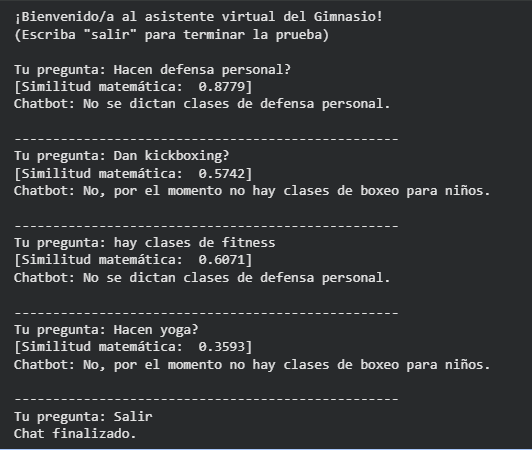

Agregué un screenshot con unas pruebas que hice, el modelo me dio puntajes altos a preguntas y respondió erróneamente porque asoció las palabras "kickboxing", "fitness" y "yoga" por ser todas disciplinas/deportes.

## 🟣 Conclusión: Comparativa de Modelos NLP

Durante el desarrollo de este asistente virtual, se evaluaron dos enfoques distintos para el procesamiento de lenguaje natural, exponiendo las ventajas y limitaciones inherentes de cada tecnología:
* **Enfoque 1: Matriz TF-IDF (Frecuencia Lexical)**
    * *Fortalezas:* Alta precisión cuando el usuario formula preguntas utilizando el vocabulario exacto del dataset. Es computacionalmente ligero, rápido y transparente.
    * *Debilidades:* Ceguera semántica. Al depender de la coincidencia exacta de tokens, el modelo es incapaz de manejar sinónimos o anglicismos de uso cotidiano (ej. no reconoce la relación entre "lockers" y "casilleros"), arrojando una similitud de cero ante consultas válidas.
* **Enfoque 2: Word Embeddings (SpaCy es_core_news_md)**
    * *Fortalezas:* Comprensión espacial del lenguaje. Logra superar la limitación del TF-IDF al identificar la intención del usuario a través de sinónimos, calculando la cercanía matemática entre conceptos (ej. asignando un puntaje válido a la relación mochila/casillero).
    * *Debilidades:* Pérdida de contexto por promediado. Al calcular el vector de una oración completa como el promedio de los vectores de sus palabras individuales, el algoritmo difumina la estructura gramatical. Esto genera "falsos positivos" al agrupar consultas con intenciones distintas (ej. "kickboxing" y "fitness") simplemente por pertenecer a un mismo dominio semántico general.

En conclusión:

La transición de TF-IDF a Word Embeddings representó una mejora sustancial en la flexibilidad del motor de búsqueda. Si bien la técnica de promediar vectores evidencia vulnerabilidades contextuales, el uso de representaciones semánticas (Embeddings) ofrece una experiencia de usuario superior al no penalizar el uso de vocabulario alternativo o sinónimos, algo en lo que el conteo estricto del TF-IDF fracasa.

### Recursos:

📌 Notebook clase 4: https://colab.research.google.com/drive/1ppozQHdu5E0dQag0G_4CQa2eLRz10QEu?usp=sharing

📌 Notebook clase 5:
https://colab.research.google.com/drive/1LJTArbSj4skMtv6TxQ9qIbmJRQ3yFssS?usp=sharing

📌 Documentación oficial de SpaCy:
https://spacy.io/usage/spacy-101#vectors-similarity